## LangGraph的节点容错机制

**`LangGraph`** 提供了三种异常处理机制

- **`retries`**：重试机制。节点执行失败时，根据重试策略自动重新执行。
- **`Timeouts`**：超时控制。限制单次节点执行的最大等待时间。
- **`Error Handling`**：错误处理。重试次数耗尽后，执行特定的异常处理逻辑。

三者的执行顺序如下：

1. 节点开始执行。
2. 如果节点执行超时或抛出异常，本次节点尝试失败。
3. 重试策略 **`RetryPolicy`** 判断该异常是否需要重试。
4. 如果满足重试条件，并且尚未达到最大尝试次数，则重新执行节点。
5. 如果重试次数耗尽，节点仍然失败，则进入 **`error_handler`** 错误处理逻辑。
6. 如果没有配置错误处理逻辑，则异常继续向外抛出，可能导致整个图运行失败。

需要注意：

* **重试机制** 是当前版本中最常用、最基础的节点容错能力。
* **超时控制** 和 **错误处理** 是较新版本引入的能力，要求 **`langgraph>=1.2`**。

### 1. 重试机制
1.1 基本用法

2026-10-20 17:48:56.932 | INFO     | __main__:node_a:12 - node a 运行
2026-10-20 17:48:57.433 | INFO     | __main__:node_a:12 - node a 运行
2026-10-20 17:48:58.435 | INFO     | __main__:node_a:12 - node a 运行
2026-10-20 17:48:58.436 | INFO     | __main__:<module>:31 - 重试次数耗尽：网络链接超时。。。


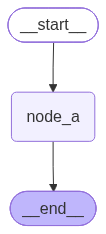

In [1]:
from typing import TypedDict
from langgraph.graph import StateGraph, START, END
from langgraph.types import RetryPolicy
from requests.exceptions import HTTPError
from loguru import logger
from IPython.display import display

class EmptyState(TypedDict):
    pass

def node_a(state: EmptyState) -> EmptyState:
    logger.info(f"node a 运行")
    raise HTTPError("网络链接超时。。。")

builder = StateGraph(state_schema=EmptyState)
builder.add_node(
    "node_a",
    node_a,
    retry_policy=RetryPolicy(
        max_attempts=3,
        jitter=False,#是否开启抖动，false指的是均匀分布
    ),
)
builder.add_edge(START, "node_a")
builder.add_edge("node_a", END)

graph = builder.compile()
try:
    graph.invoke({})
except HTTPError as e:
    logger.info("重试次数耗尽：{}", e)

display(graph)

1.2 默认重试条件

**`retry_on`** 的默认值为 **`default_retry_on`**。

**`default_retry_on`** 是一个可调用对象，它接收一个 **`Exception`** 实例，并返回一个 **`bool`** 值：

```text
True  -> 需要重试
False -> 不需要重试
```

默认情况下，**`default_retry_on`** 会对大多数异常进行重试，但以下异常及其子类通常不会触发重试：

* **`ValueError`**
* **`TypeError`**
* **`ArithmeticError`**
* **`ImportError`**
* **`LookupError`**
* **`NameError`**
* **`SyntaxError`**
* **`RuntimeError`**
* **`ReferenceError`**
* **`StopIteration`**
* **`StopAsyncIteration`**
* **`OSError`**

这些异常通常更像是代码逻辑错误、类型错误、语法错误或运行时错误，单纯重试通常没有意义。

对于主流 **`HTTP`** 库中的异常，例如 **`requests`** 和 **`httpx`**，默认策略通常只对 **`5xx`** 状态码进行重试。

原因是：

* **`4xx`** 通常表示客户端请求错误，例如参数错误、鉴权失败、资源不存在等。
* **`5xx`** 通常表示服务端异常，例如服务暂时不可用、网关错误、内部服务错误等。

### 2. 超时控制

2026-10-20 21:07:35.259 | INFO     | __main__:<module>:34 - 图编译完成
2026-10-20 21:07:35.261 | INFO     | __main__:node_a:15 - node a 运行
2026-10-20 21:07:35.263 | INFO     | __main__:<module>:40 - 重试次数耗尽：网络链接超时。。。


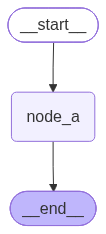

In [8]:
from typing import TypedDict
from langgraph.graph import StateGraph, START, END
from requests.exceptions import HTTPError
from loguru import logger
from IPython.display import display
from langgraph.types import TimeoutPolicy
import asyncio

# --- 状态定义 ---
class EmptyState(TypedDict):
    pass

# 改成 async def，并用asyncio.to_thread 包裹同步阻塞操作
async def node_a(state: EmptyState) -> EmptyState:
    logger.info("node a 运行")
    # 将同步的、可能阻塞的调用放到后台线程，避免阻塞事件循环
    def _sync_task():
        raise HTTPError("网络链接超时。。。")
    await asyncio.to_thread(_sync_task)


# --- 构建并编译图 ---
builder = StateGraph(state_schema=EmptyState)

builder.add_node(
    "node_a",
    node_a,
    timeout=TimeoutPolicy(run_timeout=60),
)
builder.add_edge(START, "node_a")
builder.add_edge("node_a", END)

graph = builder.compile()
logger.info("图编译完成")

# --- 执行图并处理异常 ---
try:
    await graph.ainvoke({})
except HTTPError as e:
    logger.info("重试次数耗尽：{}", e)

# --- 在 notebook 中展示图结构 ---
display(graph)